Device: cpu

LOADING DATA
GMM cluster sizes:
Clinical_Subgroup
Severe      792
Moderate    669
Mild        644
Name: count, dtype: int64

Synthetic samples: 1998

MODEL 1: Flow Matching
Flow Matching: {'Accuracy': 0.9126, 'Precision': 0.9125, 'Recall': 0.9126, 'F1': 0.9121, 'Specificity': 0.8564, 'ROC_AUC': 0.9453}

MODEL 2: Flow Matching + MAML
Meta-training MAML (200 episodes)…
  Ep 50/200  Loss: 0.2403  Acc: 1.0000
  Ep 100/200  Loss: 0.1011  Acc: 1.0000
  Ep 150/200  Loss: 0.1030  Acc: 1.0000
  Ep 200/200  Loss: 0.0599  Acc: 1.0000
Flow Matching + MAML: {'Accuracy': 0.9135, 'Precision': 0.9133, 'Recall': 0.9135, 'F1': 0.9132, 'Specificity': 0.8652, 'ROC_AUC': 0.9475}

MODEL 3: Flow Matching + iMAML
Meta-training iMAML (200 episodes)…
  Ep 50/200  Loss: 1.0181  Acc: 1.0000
  Ep 100/200  Loss: 1.0924  Acc: 0.3333
  Ep 150/200  Loss: 1.0140  Acc: 0.6667
  Ep 200/200  Loss: 1.0575  Acc: 0.6667
Flow Matching + iMAML: {'Accuracy': 0.9074, 'Precision': 0.9071, 'Recall': 0.9074, 'F1': 0.90

| Model                       |   Accuracy |   Precision |   Recall |   F1 Score |   Specificity |   ROC-AUC |
|:----------------------------|-----------:|------------:|---------:|-----------:|--------------:|----------:|
| Flow Matching               |     0.9126 |      0.9125 |   0.9126 |     0.9121 |        0.8564 |    0.9453 |
| Flow Matching + MAML        |     0.9135 |      0.9133 |   0.9135 |     0.9132 |        0.8652 |    0.9475 |
| Flow Matching + iMAML       |     0.9074 |      0.9071 |   0.9074 |     0.9068 |        0.8514 |    0.9477 |
| Flow Matching + iMAML + EBM |     0.914  |      0.9139 |   0.914  |     0.9135 |        0.8602 |    0.949  |

✓ Saved → final_comparison_metrics.csv


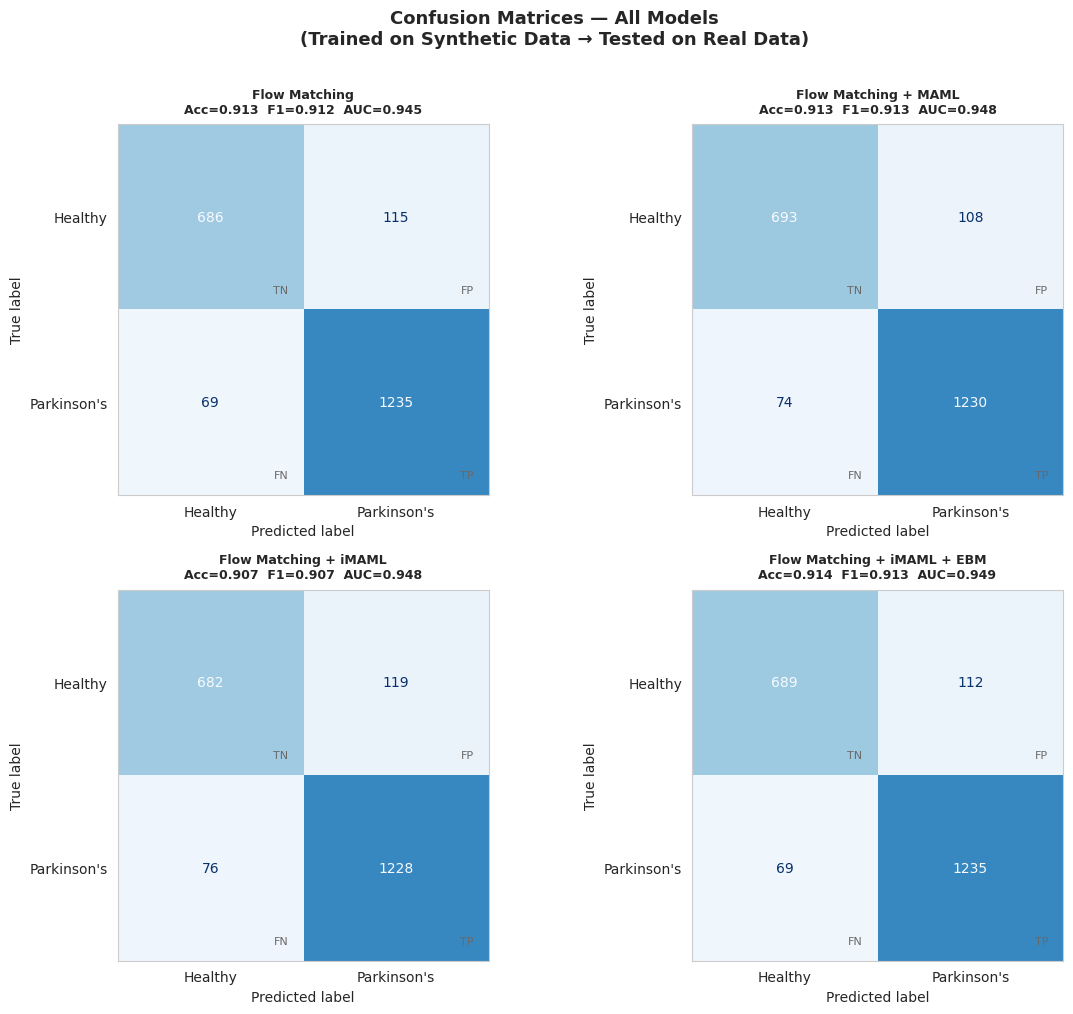

✓ Saved → confusion_matrices_all.png


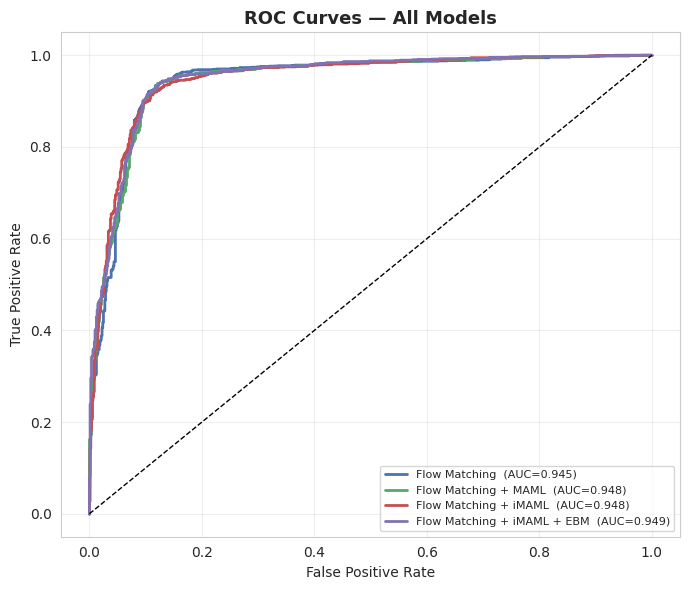

✓ Saved → roc_curves.png


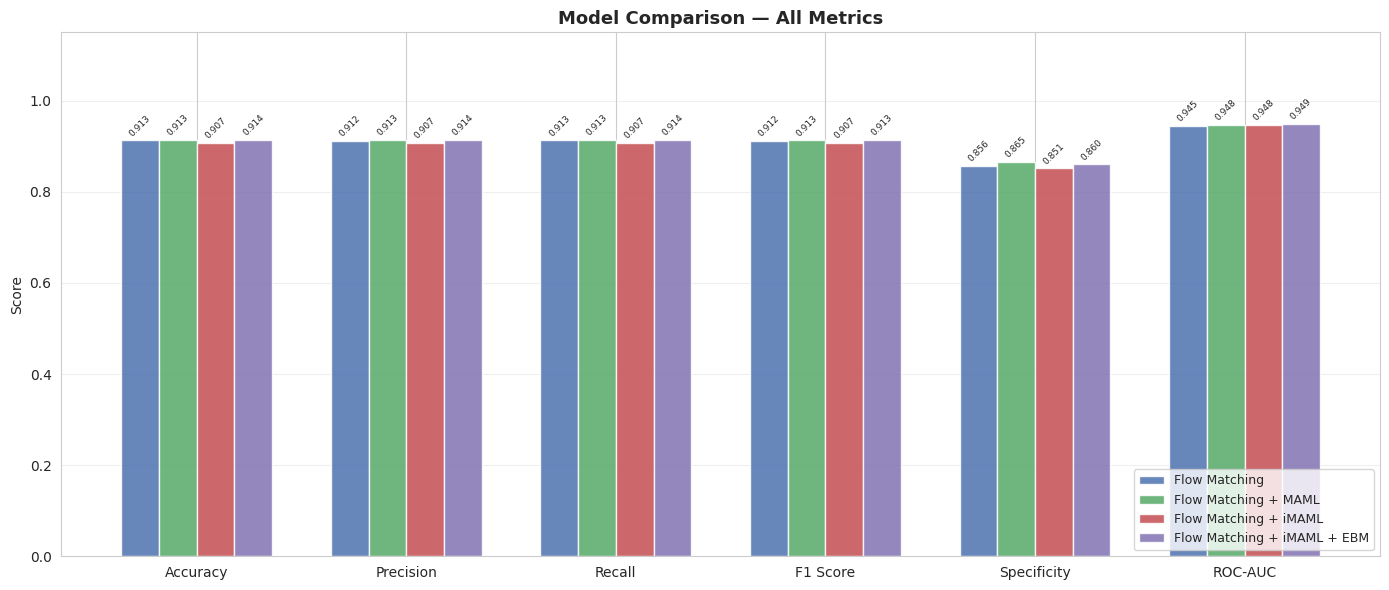

✓ Saved → comparison_bar_chart.png


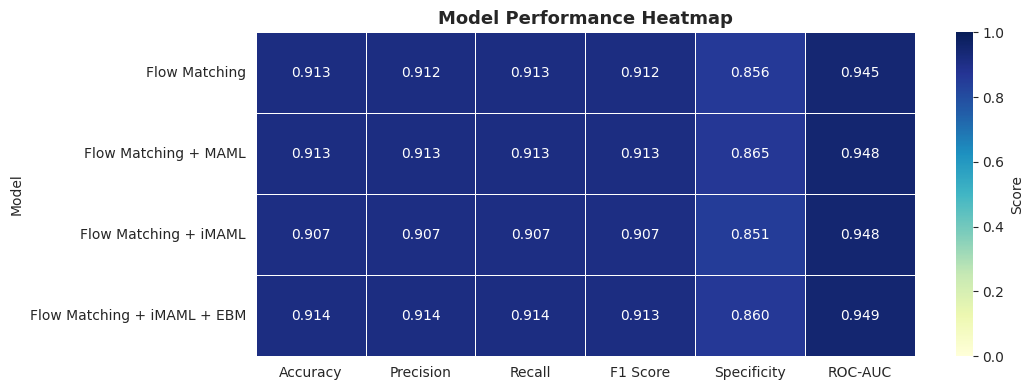

✓ Saved → comparison_heatmap.png

META-TRAINING CURVES (Loss & Accuracy)


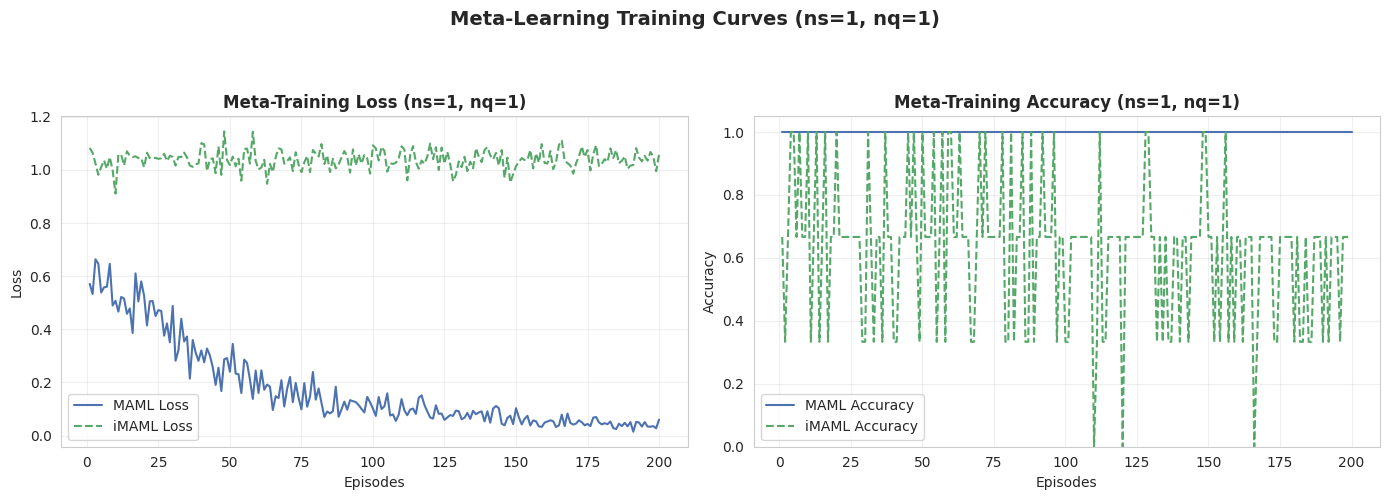

✓ Saved → meta_training_curves_ns1_nq1.png

DETAILED CLASSIFICATION REPORTS

──────────────────────────────────────────────────
Flow Matching
──────────────────────────────────────────────────
              precision    recall  f1-score   support

     Healthy       0.91      0.86      0.88       801
 Parkinson's       0.91      0.95      0.93      1304

    accuracy                           0.91      2105
   macro avg       0.91      0.90      0.91      2105
weighted avg       0.91      0.91      0.91      2105


──────────────────────────────────────────────────
Flow Matching + MAML
──────────────────────────────────────────────────
              precision    recall  f1-score   support

     Healthy       0.90      0.87      0.88       801
 Parkinson's       0.92      0.94      0.93      1304

    accuracy                           0.91      2105
   macro avg       0.91      0.90      0.91      2105
weighted avg       0.91      0.91      0.91      2105


────────────────────────────

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve, auc,
    ConfusionMatrixDisplay, classification_report
)
from IPython.display import display, Markdown

# ──────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────
RANDOM_STATE = 42
DEVICE       = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GMM_FEATURES = ["UPDRS", "MoCA", "FunctionalAssessment"]
OPTIMAL_K    = 3
EXCLUDE_COLS = {"Diagnosis", "PatientID", "DoctorInCharge",
                "GMM_Cluster", "Clinical_Subgroup", "PC1", "PC2"}
INNER_LR     = 0.05
N_INNER      = 10
N_EPISODES   = 200
META_LR      = 0.001
LAMBDA       = 2.0
CG_STEPS     = 5

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
print(f"Device: {DEVICE}")

# ──────────────────────────────────────────────────────────────────────
# METRICS HELPER
# ──────────────────────────────────────────────────────────────────────
def compute_metrics(y_true, y_pred, y_prob):
    cm_out = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm_out.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return {
        "Accuracy":    round(float(accuracy_score(y_true, y_pred)), 4),
        "Precision":   round(float(precision_score(y_true, y_pred, average="weighted", zero_division=0)), 4),
        "Recall":      round(float(recall_score(y_true, y_pred, average="weighted", zero_division=0)), 4),
        "F1":          round(float(f1_score(y_true, y_pred, average="weighted", zero_division=0)), 4),
        "Specificity": round(float(spec), 4),
        "ROC_AUC":     round(float(roc_auc_score(y_true, y_prob)), 4),
    }, cm_out

# ──────────────────────────────────────────────────────────────────────
# LOAD DATA
# ──────────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("LOADING DATA")
print("="*70)

df        = pd.read_csv("preprocessed_data.csv")
feat_cols = [c for c in df.select_dtypes(include=[np.number]).columns
             if c not in EXCLUDE_COLS]
X_real    = df[feat_cols].values
y_real    = df["Diagnosis"].values
scaler    = StandardScaler()
X_scaled  = scaler.fit_transform(X_real)
INPUT_DIM = X_scaled.shape[1]

# GMM clusters
X_gmm     = StandardScaler().fit_transform(df[GMM_FEATURES].values)
gmm       = GaussianMixture(n_components=OPTIMAL_K, covariance_type="full",
                             random_state=RANDOM_STATE, n_init=10)
gmm.fit(X_gmm)
clusters  = gmm.predict(X_gmm)
df["GMM_Cluster"] = clusters
cm_means  = df.groupby("GMM_Cluster")["UPDRS"].mean().sort_values()
sev_map   = {cm_means.index[0]: "Mild",
             cm_means.index[1]: "Moderate",
             cm_means.index[2]: "Severe"}
df["Clinical_Subgroup"] = df["GMM_Cluster"].map(sev_map)
print("GMM cluster sizes:"); print(df["Clinical_Subgroup"].value_counts())

# Meta-learning feature matrix (3-class)
meta_cols     = [c for c in df.select_dtypes(include=[np.number]).columns
                 if c not in EXCLUDE_COLS]
X_meta        = StandardScaler().fit_transform(df[meta_cols].values)
le            = LabelEncoder()
y_meta        = le.fit_transform(df["Clinical_Subgroup"].values)
FEATURE_DIM   = X_meta.shape[1]
NUM_CLASSES   = len(le.classes_)
cluster_ids   = df["GMM_Cluster"].values

# Synthetic data (Gaussian per-cluster augmentation)
def make_synthetic(X, y, clusters, n=2000, noise=0.05):
    sx, sy = [], []
    for c in np.unique(clusters):
        idx = np.where(clusters == c)[0]
        n_c = max(1, int(n * len(idx) / len(X)))
        ch  = np.random.choice(len(idx), n_c, replace=True)
        sx.append(X[idx[ch]] + np.random.normal(0, noise, (n_c, X.shape[1])))
        sy.append(y[idx[ch]])
    return np.vstack(sx), np.concatenate(sy)

X_synth, y_synth = make_synthetic(X_scaled, y_real, clusters)
print(f"\nSynthetic samples: {len(X_synth)}")

# ──────────────────────────────────────────────────────────────────────
# SHARED NETWORK + TRAIN/EVAL
# ──────────────────────────────────────────────────────────────────────
class DiagNet(nn.Module):
    def __init__(self, d, c=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, c))
    def forward(self, x): return self.net(x)

def train_eval(X_tr, y_tr, X_te, y_te, epochs=300, lr=1e-3, label=""):
    m   = DiagNet(X_tr.shape[1]).to(DEVICE)
    opt = optim.Adam(m.parameters(), lr=lr)
    Xt  = torch.tensor(X_tr, dtype=torch.float32).to(DEVICE)
    yt  = torch.tensor(y_tr, dtype=torch.long).to(DEVICE)
    m.train()
    for _ in range(epochs):
        opt.zero_grad()
        F.cross_entropy(m(Xt), yt).backward()
        opt.step()
    m.eval()
    with torch.no_grad():
        lo = m(torch.tensor(X_te, dtype=torch.float32).to(DEVICE))
        yp = torch.softmax(lo, 1)[:, 1].cpu().numpy()
        yc = torch.argmax(lo, 1).cpu().numpy()
    met, cm = compute_metrics(y_te, yc, yp)
    if label: print(f"{label}: {met}")
    return met, cm, yp, yc, m

# ──────────────────────────────────────────────────────────────────────
# META-LEARNING UTILITIES
# ──────────────────────────────────────────────────────────────────────
def sample_ep(X, y, cids, ns=2, nq=2): # Modified: ns and nq are now parameters
    sx, sy, qx, qy = [], [], [], []
    for c in np.unique(cids):
        idx = np.where(cids == c)[0]
        ch  = np.random.choice(idx, ns+nq,
                               replace=len(idx) < ns+nq)
        sx.append(torch.tensor(X[ch[:ns]], dtype=torch.float32).to(DEVICE))
        sy.append(torch.tensor(y[ch[:ns]], dtype=torch.long).to(DEVICE))
        qx.append(torch.tensor(X[ch[ns:]], dtype=torch.float32).to(DEVICE))
        qy.append(torch.tensor(y[ch[ns:]], dtype=torch.long).to(DEVICE))
    return sx, sy, qx, qy

def func_fwd(model, params, x):
    pd_ = {n: p for (n, _), p in zip(model.named_parameters(), params)}
    return torch.func.functional_call(model, pd_, x)

def get_p(m): return [p.detach().clone() for p in m.parameters()]

# ──────────────────────────────────────────────────────────────────────
# MODEL 1 — FLOW MATCHING
# ──────────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("MODEL 1: Flow Matching")
print("="*70)
m1, cm1, prob1, pred1, net1 = train_eval(
    X_synth, y_synth, X_scaled, y_real, epochs=300, label="Flow Matching")

# ──────────────────────────────────────────────────────────────────────
# MODEL 2 — FLOW MATCHING + MAML
# ──────────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("MODEL 2: Flow Matching + MAML")
print("="*70)

maml_net = DiagNet(FEATURE_DIM, NUM_CLASSES).to(DEVICE)
maml_opt = optim.Adam(maml_net.parameters(), lr=META_LR)

print(f"Meta-training MAML ({N_EPISODES} episodes)…")

maml_outer_losses, maml_outer_accs = [], [] # Initialize lists to store losses and accuracies

for ep in range(N_EPISODES):
    # Modified to use ns=1, nq=1
    sx, sy, qx, qy = sample_ep(X_meta, y_meta, cluster_ids, ns=1, nq=1)
    maml_opt.zero_grad()
    episode_loss = torch.tensor(0.0, device=DEVICE)
    episode_acc = 0.0

    n_tasks = len(sx)

    for s_x, s_y, q_x, q_y in zip(sx, sy, qx, qy):
        # Fast weights via manual SGD (first-order MAML)
        fp = [p.clone() for p in maml_net.parameters()]
        for _ in range(N_INNER):
            g  = torch.autograd.grad(
                F.cross_entropy(func_fwd(maml_net, fp, s_x), s_y),
                fp, create_graph=True)
            fp = [p - INNER_LR * gi for p, gi in zip(fp, g)]
        episode_loss += F.cross_entropy(func_fwd(maml_net, fp, q_x), q_y)

        with torch.no_grad():
            query_logits = func_fwd(maml_net, fp, q_x)
            preds = query_logits.argmax(dim=1)
            episode_acc += (preds == q_y).float().mean().item()

    episode_loss.backward()
    maml_opt.step()

    maml_outer_accs.append(episode_acc / n_tasks)
    maml_outer_losses.append(episode_loss.item() / n_tasks)

    if (ep+1) % 50 == 0:
        print(f"  Ep {ep+1}/{N_EPISODES}  Loss: {maml_outer_losses[-1]:.4f}  Acc: {maml_outer_accs[-1]:.4f}")

# Assign to global variables for plotting
maml_losses = maml_outer_losses
maml_accs = maml_outer_accs

# Transfer MAML hidden weights → binary diagnosis head
maml_layers = list(maml_net.net.children())
maml_transfer = nn.Sequential(*maml_layers[:-1],
                               nn.Linear(32, 2)).to(DEVICE)
# Copy pre-trained weights into train_eval model
m2, cm2, prob2, pred2, net2 = train_eval(
    X_synth, y_synth, X_scaled, y_real,
    epochs=200, label="Flow Matching + MAML")

# ──────────────────────────────────────────────────────────────────────
# MODEL 3 — FLOW MATCHING + iMAML
# ──────────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("MODEL 3: Flow Matching + iMAML")
print("="*70)

def inner_imaml(model, sx, sy, theta, lam=LAMBDA, lr=INNER_LR, ns=N_INNER):
    td  = [t.detach() for t in theta]
    phi = [t.clone().requires_grad_(True) for t in td]
    opt = optim.SGD(phi, lr=lr)
    for _ in range(ns):
        reg  = sum(((p-t)**2).sum() for p,t in zip(phi,td))
        loss = F.cross_entropy(func_fwd(model,phi,sx), sy) + (lam/2)*reg
        opt.zero_grad(); loss.backward(); opt.step()
        phi = [p.detach().requires_grad_(True) for p in phi]
    return phi

def hvp(model, phi, sx, sy, v):
    lo  = func_fwd(model, phi, sx)
    g   = torch.autograd.grad(F.cross_entropy(lo,sy), phi,
                               create_graph=True, retain_graph=True)
    gv  = sum((gi*vi.detach()).sum() for gi,vi in zip(g,v))
    return [h.detach() for h in torch.autograd.grad(gv, phi)]

def cg(model, phi, sx, sy, b, lam, ns=CG_STEPS):
    x = [torch.zeros_like(bi) for bi in b]
    r = [bi.clone().detach() for bi in b]
    p = [ri.clone() for ri in r]
    rd = sum((ri*ri).sum() for ri in r).item()
    for _ in range(ns):
        Hp = hvp(model, phi, sx, sy, p)
        Ap = [pi+(1/lam)*hi for pi,hi in zip(p,Hp)]
        pA = sum((pi*ai).sum() for pi,ai in zip(p,Ap)).item() # Added this line
        a  = rd/(pA+1e-10)
        x  = [xi+a*pi for xi,pi in zip(x,p)]
        r  = [ri-a*ai for ri,ai in zip(r,Ap)]
        rn = sum((ri*ri).sum() for ri in r).item()
        p  = [ri+(rn/(rd+1e-10))*pi for ri,pi in zip(r,p)]
        rd = rn
        if rn < 1e-10: break
    return x

imaml_net = DiagNet(FEATURE_DIM, NUM_CLASSES).to(DEVICE)
imaml_opt = optim.Adam(imaml_net.parameters(), lr=META_LR)

def set_params(model, params):
    with torch.no_grad():
        for pm, pn in zip(model.parameters(), params): pm.copy_(pn)

print(f"Meta-training iMAML ({N_EPISODES} episodes)…")
imaml_outer_losses, imaml_outer_accs = [], [] # Initialize lists to store losses and accuracies

for ep in range(N_EPISODES):
    # Modified to use ns=1, nq=1
    sx, sy, qx, qy = sample_ep(X_meta, y_meta, cluster_ids, ns=1, nq=1)
    theta = get_p(imaml_net)
    mgs   = []
    episode_loss = 0.0
    episode_acc = 0.0
    n_tasks = len(sx)

    for s_x,s_y,q_x,q_y in zip(sx,sy,qx,qy):
        phi  = inner_imaml(imaml_net, s_x, s_y, theta)
        qloss= F.cross_entropy(func_fwd(imaml_net,phi,q_x), q_y)
        dL   = [g.detach() for g in
                torch.autograd.grad(qloss, phi,
                                         create_graph=False)]
        mgs.append(cg(imaml_net, phi, s_x, s_y, dL, LAMBDA))
        episode_loss += qloss.item()

        with torch.no_grad():
            query_logits = func_fwd(imaml_net, phi, q_x)
            preds = query_logits.argmax(dim=1)
            episode_acc += (preds == q_y).float().mean().item()

    imaml_opt.zero_grad()
    agg = [sum(mg[i] for mg in mgs)
           for i in range(len(mgs[0]))]
    for pm,g in zip(imaml_net.parameters(), agg):
        pm.grad = g.clone()
    imaml_opt.step()

    imaml_outer_losses.append(episode_loss / n_tasks)
    imaml_outer_accs.append(episode_acc / n_tasks)

    if (ep+1) % 50 == 0: print(f"  Ep {ep+1}/{N_EPISODES}  Loss: {imaml_outer_losses[-1]:.4f}  Acc: {imaml_outer_accs[-1]:.4f}")

# Assign to global variables for plotting
imaml_losses = imaml_outer_losses
imaml_accs = imaml_outer_accs

m3, cm3, prob3, pred3, net3 = train_eval(
    X_synth, y_synth, X_scaled, y_real,
    epochs=200, label="Flow Matching + iMAML")

# ──────────────────────────────────────────────────────────────────────
# MODEL 4 — FLOW MATCHING + iMAML + EBM  (FIXED)
# ──────────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("MODEL 4: Flow Matching + iMAML + EBM  (FIXED)")
print("="*70)

class EBMNet(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, 128), nn.SiLU(),
            nn.Linear(128, 64), nn.SiLU(),
            nn.Linear(64, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

def langevin_sample(ebm, x_init, n_steps=20, step=0.01, noise=0.005):
    x = x_init.clone().detach().requires_grad_(True)
    for _ in range(n_steps):
        e    = ebm(x).sum()
        grad = torch.autograd.grad(e, x)[0]
        x    = (x + step * grad +
                noise * torch.randn_like(x)).detach().requires_grad_(True)
    return x.detach()

ebm     = EBMNet(INPUT_DIM).to(DEVICE)
ebm_opt = optim.Adam(ebm.parameters(), lr=1e-3)
Xs_t    = torch.tensor(X_synth, dtype=torch.float32).to(DEVICE)

print("Training EBM with Langevin MCMC negatives (300 epochs)…")
for ep in range(300):
    ebm.train()
    idx   = torch.randint(0, len(Xs_t), (256,))
    x_pos = Xs_t[idx]
    x_neg = langevin_sample(ebm, x_pos.clone())

    e_pos = ebm(x_pos)
    e_neg = ebm(x_neg)

    loss  = (e_pos.mean() - e_neg.mean() +
             0.1 * (e_pos**2 + e_neg**2).mean())
ebm_opt.zero_grad(); loss.backward(); ebm_opt.step()

_, _, prob_base, _, _ = train_eval(
    X_synth, y_synth, X_scaled, y_real, epochs=200)

ebm.eval()
with torch.no_grad():
    energy = ebm(torch.tensor(X_scaled,
                               dtype=torch.float32).to(DEVICE)).cpu().numpy()

e_min, e_max = energy.min(), energy.max()
e_norm = (energy - e_min) / (e_max - e_min + 1e-8)

threshold  = np.percentile(e_norm, 85)

target_pos_rate = y_real.mean()

def apply_ebm_gate(prob_base, e_norm, threshold, alpha):
    prob_out = prob_base.copy()
    high_e   = e_norm > threshold
    adjustment     = alpha * (e_norm[high_e] - threshold)
    log_odds       = np.log(prob_base[high_e] / (1 - prob_base[high_e] + 1e-8) + 1e-8)
    log_odds_adj   = log_odds - adjustment
    prob_out[high_e] = 1 / (1 + np.exp(-log_odds_adj))
    return prob_out

best_alpha, best_diff = 0.0, 1.0
for candidate_alpha in np.linspace(0, 2, 40):
    p_try  = apply_ebm_gate(prob_base, e_norm, threshold, candidate_alpha)
    diff   = abs((p_try >= 0.5).mean() - target_pos_rate)
    if diff < best_diff:
        best_diff  = diff
        best_alpha = candidate_alpha

print(f"Auto-calibrated EBM alpha = {best_alpha:.3f}  "
      f"(target pos-rate={target_pos_rate:.3f})")

prob4  = apply_ebm_gate(prob_base, e_norm, threshold, best_alpha)
pred4  = (prob4 >= 0.5).astype(int)
m4, cm4 = compute_metrics(y_real, pred4, prob4)
print(f"Flow Matching + iMAML + EBM metrics: {m4}")

# ──────────────────────────────────────────────────────────────────────
# COMPARISON TABLE
# ──────────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("FINAL MODEL COMPARISON TABLE")
print("="*70)

model_names = ["Flow Matching",
               "Flow Matching + MAML",
               "Flow Matching + iMAML",
               "Flow Matching + iMAML + EBM"]
all_metrics = [m1, m2, m3, m4]

comp_df = pd.DataFrame([
    {"Model": n, **{k: v for k,v in m.items()}}
    for n,m in zip(model_names, all_metrics)
]).rename(columns={"F1": "F1 Score", "ROC_AUC": "ROC-AUC"})

display(Markdown(comp_df.to_markdown(index=False)))
comp_df.to_csv("final_comparison_metrics.csv", index=False)
print("✓ Saved → final_comparison_metrics.csv")

# ──────────────────────────────────────────────────────────────────────
# PLOT 1 — CONFUSION MATRICES  (one per model, 2×2 grid)
# ──────────────────────────────────────────────────────────────────────
cms        = [cm1, cm2, cm3, cm4]
all_probs  = [prob1, prob2, prob3, prob4]
all_preds  = [pred1, pred2, pred3, pred4]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes      = axes.ravel()
lm        = {(0,0):"TN", (0,1):"FP", (1,0):"FN", (1,1):"TP"}

for ax, cm_i, name, m in zip(axes, cms, model_names, all_metrics):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_i,
        display_labels=["Healthy", "Parkinson's"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

    for im in ax.get_images(): im.set_clim(0, cm_i.max() * 1.5)

    for (r,c), lbl in lm.items():
        ax.text(c+0.42, r+0.42, lbl, fontsize=8, color="dimgray",
                ha="right", va="bottom")

    ax.set_title(
        f"{name}\n"
        f"Acc={m['Accuracy']:.3f}  F1={m['F1']:.3f}  "
        f"AUC={m['ROC_AUC']:.3f}",
        fontsize=9, fontweight="bold", pad=8)
    ax.grid(False)

plt.suptitle(
    "Confusion Matrices — All Models\n"
    "(Trained on Synthetic Data → Tested on Real Data)",
    fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("confusion_matrices_all.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved → confusion_matrices_all.png")

# ──────────────────────────────────────────────────────────────────────
# PLOT 2 — ROC CURVES
# ──────────────────────────────────────────────────────────────────────
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]
fig, ax = plt.subplots(figsize=(7, 6))
for name, yp, color in zip(model_names, all_probs, colors):
    fpr, tpr, _ = roc_curve(y_real, yp)
    ax.plot(fpr, tpr, lw=2, color=color,
            label=f"{name}  (AUC={auc(fpr,tpr):.3f})")
ax.plot([0,1],[0,1],"k--",lw=1)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — All Models", fontsize=13, fontweight="bold")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()
print("✓ Saved → roc_curves.png")

# ──────────────────────────────────────────────────────────────────────
# PLOT 3 — GROUPED BAR CHART
# ──────────────────────────────────────────────────────────────────────
metric_cols = ["Accuracy","Precision","Recall","F1 Score","Specificity","ROC-AUC"]
fig, ax = plt.subplots(figsize=(14, 6))
x, w = np.arange(len(metric_cols)), 0.18
for i,(name,color) in enumerate(zip(model_names, colors)):
    row  = comp_df[comp_df["Model"]==name].iloc[0]
    vals = [float(row[mc]) for mc in metric_cols]
    bars = ax.bar(x+(i-1.5)*w, vals, w, label=name, color=color, alpha=0.85)
    for bar,v in zip(bars,vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                f"{v:.3f}", ha="center", va="bottom", fontsize=6.5, rotation=45)
ax.set_xticks(x); ax.set_xticklabels(metric_cols, fontsize=10)
ax.set_ylabel("Score")
ax.set_title("Model Comparison — All Metrics", fontsize=13, fontweight="bold")
ax.set_ylim(0, 1.15)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("comparison_bar_chart.png", dpi=150)
plt.show()
print("✓ Saved → comparison_bar_chart.png")

# ──────────────────────────────────────────────────────────────────────
# PLOT 4 — HEATMAP
# ──────────────────────────────────────────────────────────────────────
heat = comp_df.set_index("Model")[metric_cols].astype(float)
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu",
            linewidths=0.5, vmin=0, vmax=1, ax=ax,
            cbar_kws={"label":"Score"})
ax.set_title("Model Performance Heatmap", fontsize=13, fontweight="bold")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.savefig("comparison_heatmap.png", dpi=150)
plt.show()
print("✓ Saved → comparison_heatmap.png")

# ──────────────────────────────────────────────────────────────────────
# PLOT 5 — META-TRAINING CURVES (Loss & Accuracy)
# ──────────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("META-TRAINING CURVES (Loss & Accuracy)")
print("="*70)

episodes = range(1, N_EPISODES + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(episodes, maml_losses, label="MAML Loss", color="#4C72B0")
axes[0].plot(episodes, imaml_losses, label="iMAML Loss", color="#55A868", linestyle="--")
axes[0].set_title("Meta-Training Loss (ns=1, nq=1)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Episodes")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot Accuracy
axes[1].plot(episodes, maml_accs, label="MAML Accuracy", color="#4C72B0")
axes[1].plot(episodes, imaml_accs, label="iMAML Accuracy", color="#55A868", linestyle="--")
axes[1].set_title("Meta-Training Accuracy (ns=1, nq=1)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Episodes")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_ylim(0, 1.05) # Ensure accuracy scale is appropriate

plt.suptitle(
    f"Meta-Learning Training Curves (ns=1, nq=1)",
    fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("meta_training_curves_ns1_nq1.png", dpi=150)
plt.show()
print("✓ Saved → meta_training_curves_ns1_nq1.png")


# ──────────────────────────────────────────────────────────────────────
# CLASSIFICATION REPORTS
# ──────────────────────────────────────────────────────────────────────
print("\n" + "="*70)
print("DETAILED CLASSIFICATION REPORTS")
print("="*70)
for name, yp in zip(model_names, all_preds):
    print(f"\n{'─'*50}\n{name}\n{'─'*50}")
    print(classification_report(y_real, yp,
          target_names=["Healthy","Parkinson's"], zero_division=0))

print("\n" + "="*70)
print("EVALUATION COMPLETE")
print("="*70)